In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("thyroid_dataset.csv")

In [3]:
df.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured,Outlier_label
0,0.45,1,0,0,0,0,0,0,0,0,...,0,0,0,0,61.0,6.0,23.0,87.0,26.0,o
1,0.61,0,0,0,0,1,0,0,0,0,...,0,0,0,0,29.0,15.0,61.0,96.0,64.0,o
2,0.16,0,1,0,0,0,0,0,0,0,...,0,1,0,0,29.0,19.0,58.0,103.0,56.0,o
3,0.85,0,0,0,0,0,0,0,0,0,...,0,0,0,0,114.0,3.0,24.0,61.0,39.0,o
4,0.75,1,0,0,0,0,0,0,0,0,...,0,0,0,0,49.0,3.0,5.0,116.0,4.0,o


In [4]:
df.shape

(6916, 22)

In [5]:
x = df.drop("Outlier_label", axis = 1)

In [6]:
y = df["Outlier_label"]

In [7]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [8]:
from sklearn.ensemble import IsolationForest

isf = IsolationForest(
    n_estimators = 200,
    contamination = 'auto',
    random_state = 42
)



In [9]:
labels = isf.fit_predict(x_scaled)

In [11]:
# Visualze

from sklearn.decomposition import PCA 

pca = PCA(n_components = 2)

x_pca = pca.fit_transform(x_scaled)

Text(0, 0.5, 'PCA2')

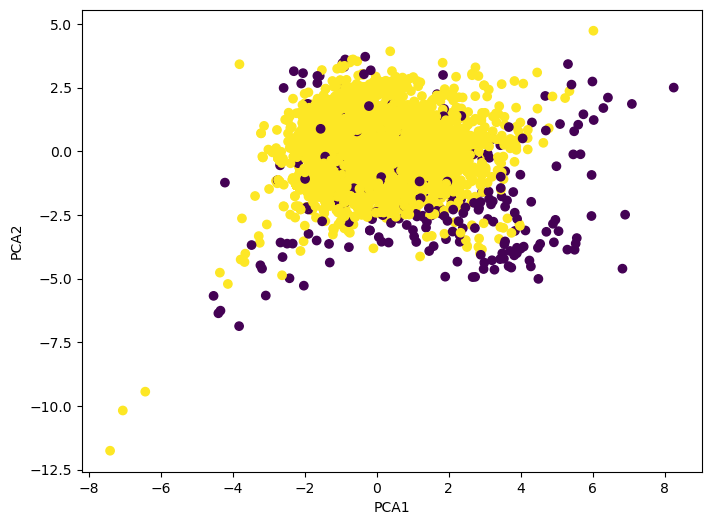

In [15]:
plt.figure(figsize = (8,6))
plt.scatter(x=x_pca[:,0], y = x_pca[:,1], c = labels)
plt.xlabel("PCA1")
plt.ylabel("PCA2")

In [16]:
import numpy as np

n_outliers = np.sum(labels == -1)
n_normal = np.sum(labels == 1)

In [18]:
print("Outlier = ", n_outliers)
print("normal = ", n_normal)

Outlier =  270
normal =  6646


# LOF - Local Outlier Factor

In [20]:
from sklearn.neighbors import LocalOutlierFactor

In [22]:
lof = LocalOutlierFactor()
labels = lof.fit_predict(x_scaled)

In [23]:
from sklearn.decomposition import PCA 

pca = PCA(n_components = 2)

x_pca = pca.fit_transform(x_scaled)

Text(0, 0.5, 'PCA2')

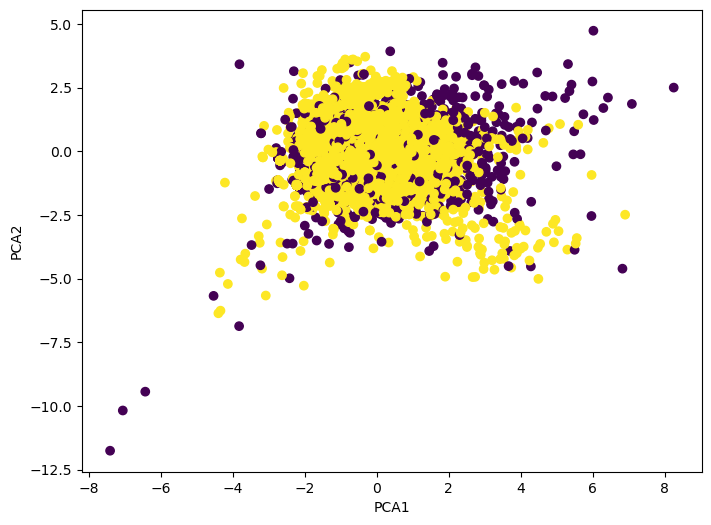

In [24]:
plt.figure(figsize = (8,6))
plt.scatter(x=x_pca[:,0], y = x_pca[:,1], c = labels)
plt.xlabel("PCA1")
plt.ylabel("PCA2")

In [25]:
import numpy as np

n_outliers = np.sum(labels == -1)
n_normal = np.sum(labels == 1)

In [26]:
print("Outlier = ", n_outliers)
print("normal = ", n_normal)

Outlier =  883
normal =  6033
